# H100 실험 결과

8개 설정과 선택 설정의 seed 3개, 동일 분할의 Linear 비교를 완료했습니다. **이번 Conv1D는 Linear보다 성능이 나빴습니다.**

| 모델 | Music EER ↓ | File EER ↓ |
|---|---:|---:|
| 공식 베이스라인 | 0.5528 | 0.4321 |
| 동일 분할 Linear | **0.3667** | **0.3519** |
| T7 seed 41 | 0.5472 | 0.3801 |
| T7 seed 42 | 0.6000 | 0.3962 |
| T7 seed 43 | 0.5528 | 0.4000 |

선택 설정은 learning rate 1e-4, Dropout 0.4, weight decay 0.05, batch 16입니다. seed별 best epoch는 1·2·1이며, 21·22·21 epoch에서 Early stopping이 작동했습니다.

공개 자료를 다시 나눈 평가입니다. 과거 dev을 재사용했으므로 새 외부 검증이나 리더보드 개선의 근거로 삼을 수 없습니다. Voice presence AUC를 계산할 정답 클래스가 부족해 종합 점수는 계산하지 않았습니다.

이 파일은 서버 실행 노트북의 출력과 실제 저장된 comparison.png를 모은 보고용 사본입니다. 원래 실행 기록은 unpacked/Temporal_H100_Executed.ipynb에 보존했습니다. 아래 그림은 서버에서 생성한 PNG를 첨부한 것이며, 표시를 위해 학습을 다시 실행하지 않았습니다.

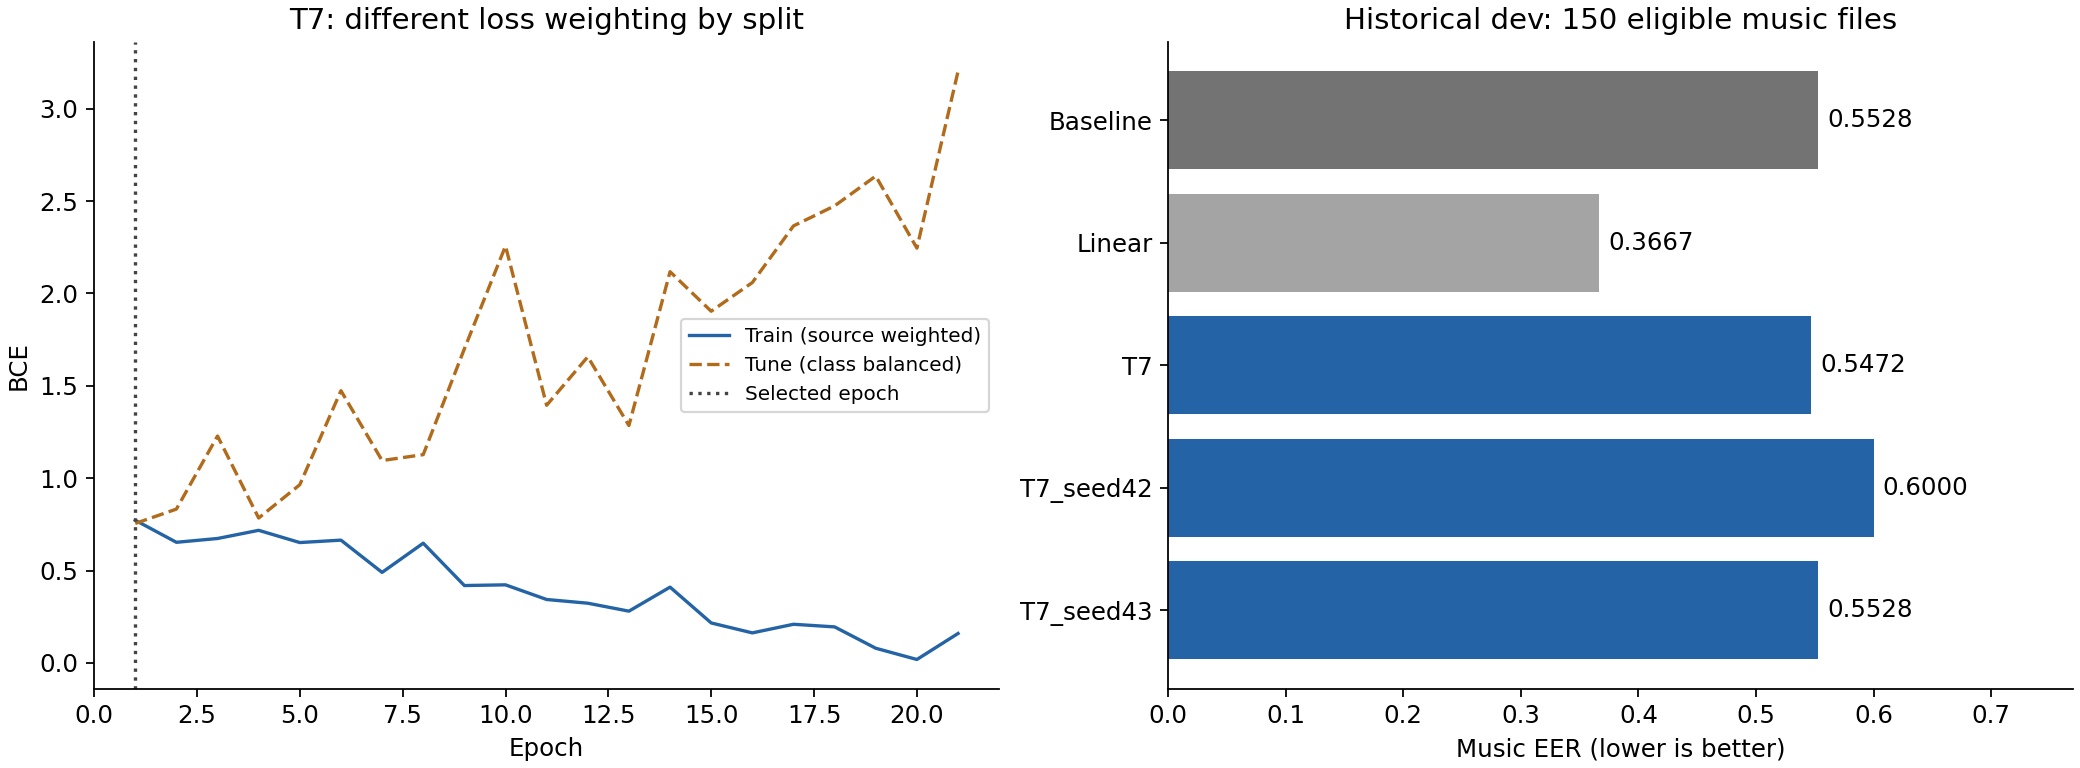

# H100 MERT Conv1D 하이퍼파라미터 비교 실험

6층 residual Conv1D + gated attention/max pooling 음악 분류기를 비교합니다. 실행 결과는 아래 셀에 저장됩니다.

- 고정: frozen MERT 768차원, hidden 128, dilation 1·2·4, batch 16, AdamW, gradient clipping 1.0, 최대 300 epoch.
- 비교: learning rate `3e-4 / 1e-4` × Dropout `0.2 / 0.4` × weight decay `0.01 / 0.05` = 8개.
- Early stopping: 튜닝 자료의 class-balanced BCE, patience 20, min_delta 1e-4, 최저 BCE 가중치 복원.
- 설정 선택: 튜닝 Music EER → 동률이면 balanced BCE. 선택 후 seed 41·42·43 모두 평가하며 평가 점수로 seed를 고르지 않습니다.
- 비교군: 기존 공식 베이스라인의 실제 저장 예측, 동일 분할로 새로 학습한 C3 Linear.
- 최대 계산 시간: 워크스페이스 시작부터 2시간. 15분 간격 확인 후 결과 다운로드·검증·Pause.

## 해석 범위
기존 공개 train·dev·sealed 자료를 재사용합니다. 원본 그룹과 혼합 부모를 분리하며 이번 설정 선택에는 최종 평가 자료를 사용하지 않습니다. 이 평가 자료는 과거에 검토한 dev이므로 새 외부 검증 자료는 아닙니다. 공개 리더보드 성능과 동일하게 해석하지 않습니다. Presence 정답이 부족한 경우 종합 점수는 계산하지 않습니다. C3 전체학습 가중치는 불러오지 않습니다.

미국 리전 CPU 작업에서 원본 음원 해시를 검증한 뒤 내보낸 1,446개 캐시를 사용합니다. H100에서 캐시 해시와 원래 추출 식별자를 다시 확인합니다. 분할은 locked_split.json으로 고정합니다.

## 1. 환경과 입력 확인

In [1]:
from pathlib import Path
import json, os, sys, time
import numpy as np
import torch
from IPython.display import display, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from v6_data import sha256, write_json
from temporal_experiment import split_experiment, load_features, training_masks, run_search, evaluate_locked_test
OUT = ROOT / 'results'; OUT.mkdir(exist_ok=True)
PROJECT = Path('/root/V6_L40S'); FINAL = Path('/root/C3_Final')
DEADLINE = float(os.environ['V7_RESUMED_EPOCH']) + 2 * 3600
manifest = json.loads((ROOT / 'input_manifest.json').read_text())
for name, digest in manifest['sha256'].items():
    assert sha256(ROOT / name) == digest, name
assert torch.cuda.is_available() and time.time() < DEADLINE
torch.set_num_threads(4)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.use_deterministic_algorithms(True)
write_json(OUT / 'environment.json', dict(gpu=torch.cuda.get_device_name(), torch=torch.__version__,
    python=sys.version, deadline=DEADLINE, deterministic_algorithms=True))
print({'GPU': torch.cuda.get_device_name(), 'torch': torch.__version__, 'compute_hours': 2})

{'GPU': 'NVIDIA H100 80GB HBM3', 'torch': '2.9.1+cu130', 'compute_hours': 2}


## 2. 분할과 캐시 검증
기존 C3 정제 정책을 유지합니다. PCM 중복과 유효 구간 없는 자료를 제외하고, 학습 자료에만 활성 프레임 비율 20% 기준 마스크를 적용합니다. 평가 자료에는 학습용 마스크를 적용하지 않습니다.

In [2]:
PLAN = json.loads((ROOT / 'full_data_plan.json').read_text())
BASELINE = json.loads((ROOT / 'baseline_predictions.json').read_text())
SPLIT = json.loads((ROOT / 'locked_split.json').read_text())
from v6_data import assert_disjoint
for a,b in [('train','tune'),('train','test'),('tune','test')]:
    assert_disjoint(SPLIT[a], SPLIT[b])
write_json(OUT / 'split.json', SPLIT)
records = load_features(SPLIT['train'] + SPLIT['tune'] + SPLIT['test'], PROJECT, FINAL)
masked = training_masks(SPLIT['train'], records, PLAN['quality'])
write_json(OUT / 'input_verification.json', dict(files=len(records), input_sha256=manifest['sha256'],
    split_sha256=sha256(OUT / 'split.json'), quality_policy=PLAN['policy'],
    baseline_sha256=sha256(ROOT / 'baseline_predictions.json'),
    cache_validation='Source audio SHA256 checked by CPU exporter; exact cache SHA256 and original identity checked on H100'))
from collections import Counter
for name, rows in SPLIT.items():
    print(name, len(rows), dict(Counter(r['source'].split('/')[0] for r in rows)))

train 1008 {'Echoes': 857, 'nsynth': 90, 'FMA': 61}
tune 248 {'FMA': 19, 'Echoes': 129, 'mixture': 80, 'splice': 20}
test 190 {'splice': 20, 'mixture': 80, 'Echoes': 40, 'MLAAD': 40, 'FMA': 10}


## 3. 8개 설정 비교 및 seed 반복
이 함수에는 최종 평가 자료를 전달하지 않습니다. 후보별 가중치와 epoch 진행 상황을 저장하고, 설정 선택을 selection.json에 고정한 뒤 seed 42·43을 추가 학습합니다. 최대 시간에 도달하면 완료된 후보와 마지막 best checkpoint를 보존합니다.

In [3]:
search = run_search(SPLIT['train'], SPLIT['tune'], records, masked, OUT, DEADLINE)
header = '| 설정 | LR | Dropout | Weight decay | 튜닝 Music EER | best epoch | 학습 epoch | 시간(s) |'
lines = [header, '|---|---:|---:|---:|---:|---:|---:|---:|']
for r in search:
    p=r['recipe']
    lines.append(f"| {r['name']} | {p['learning_rate']} | {p['dropout']} | {p['weight_decay']} | {r['music_eer']:.4f} | {r['selected_epoch']} | {r['epochs_completed']} | {r['seconds']:.1f} |")
display(Markdown('\n'.join(lines)))
print('Selected:', json.loads((OUT / 'selection.json').read_text())['winner']['name'])

T0 {'music_eer': 0.47935389846975957, 'balanced_bce': 0.7741246390896241} epochs 22


T1 {'music_eer': 0.47935389846975957, 'balanced_bce': 0.8749761367943707} epochs 22


T2 {'music_eer': 0.416848838150757, 'balanced_bce': 0.9981868671769594} epochs 22


T3 {'music_eer': 0.39118290017002677, 'balanced_bce': 0.9893805496878467} epochs 22


T4 {'music_eer': 0.3627236660999109, 'balanced_bce': 0.727493005980952} epochs 21


T5 {'music_eer': 0.3627236660999109, 'balanced_bce': 0.7280916836514215} epochs 21


T6 {'music_eer': 0.3599303700105254, 'balanced_bce': 0.7628644552179069} epochs 21


T7 {'music_eer': 0.3498906971095458, 'balanced_bce': 0.7547810927089393} epochs 21


| 설정 | LR | Dropout | Weight decay | 튜닝 Music EER | best epoch | 학습 epoch | 시간(s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| T0 | 0.0003 | 0.2 | 0.01 | 0.4794 | 2 | 22 | 14.6 |
| T1 | 0.0003 | 0.2 | 0.05 | 0.4794 | 2 | 22 | 11.7 |
| T2 | 0.0003 | 0.4 | 0.01 | 0.4168 | 2 | 22 | 11.6 |
| T3 | 0.0003 | 0.4 | 0.05 | 0.3912 | 2 | 22 | 11.9 |
| T4 | 0.0001 | 0.2 | 0.01 | 0.3627 | 1 | 21 | 10.9 |
| T5 | 0.0001 | 0.2 | 0.05 | 0.3627 | 1 | 21 | 10.8 |
| T6 | 0.0001 | 0.4 | 0.01 | 0.3599 | 1 | 21 | 10.8 |
| T7 | 0.0001 | 0.4 | 0.05 | 0.3499 | 1 | 21 | 10.7 |

Selected: T7


## 4. 고정한 모델의 성능 평가
동일한 최종 평가 190개에서 비교합니다. 음악 확률을 교체할 때 파일 확률은 베이스라인의 max 결합으로 계산합니다. 음성·존재 확률은 기존 베이스라인 값을 유지합니다. 제출 ZIP에 통합한 실행 시간 검증은 이번 실험 범위에 포함하지 않습니다.

In [4]:
reports = evaluate_locked_test(SPLIT['test'], records, BASELINE, OUT)
lines = ['| 모델 | Music EER | File EER | Balanced BCE |', '|---|---:|---:|---:|']
for r in reports:
    file_eer=r['metrics']['metrics']['file_eer']
    lines.append(f"| {r['name']} | {r['music_eer']:.4f} | {file_eer:.4f} | {r['balanced_bce']:.4f} |")
display(Markdown('\n'.join(lines)))
values = np.array([r['music_eer'] for r in reports[2:]])
print('Temporal seed Music EER mean / population std:', float(values.mean()), float(values.std()))
print('총점 계산 가능 여부:', reports[0]['metrics']['score'])

| 모델 | Music EER | File EER | Balanced BCE |
|---|---:|---:|---:|
| Official_baseline | 0.5528 | 0.4321 | 1.0845 |
| Linear_same_split | 0.3667 | 0.3519 | 0.6402 |
| T7 | 0.5472 | 0.3801 | 0.7883 |
| T7_seed42 | 0.6000 | 0.3962 | 0.8426 |
| T7_seed43 | 0.5528 | 0.4000 | 0.8648 |

Temporal seed Music EER mean / population std: 0.5666666666666667 0.02367909602323038
총점 계산 가능 여부: None


## 5. 학습 곡선과 비교 결과

In [5]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
winner=json.loads((OUT/'selection.json').read_text())['winner']['name']
trace=json.loads((OUT/winner/'training.json').read_text())
fig, axes=plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
axes[0].plot(np.arange(1,len(trace['train_losses'])+1), trace['train_losses'], label='Train (source weighted)', color='#2463a5')
axes[0].plot(np.arange(1,len(trace['validation_losses'])+1), trace['validation_losses'], label='Tune (class balanced)', color='#b16b1b', linestyle='--')
axes[0].axvline(trace['selected_epoch'], color='#444444', linestyle=':', label='Selected epoch')
axes[0].set(xlabel='Epoch', ylabel='BCE', title=f'{winner}: different loss weighting by split')
axes[0].legend(fontsize=9)
labels=[r['name'].replace('Official_baseline','Baseline').replace('Linear_same_split','Linear') for r in reports]
y=[r['music_eer'] for r in reports]
bars=axes[1].barh(labels, y, color=['#737373','#a4a4a4','#2463a5','#2463a5','#2463a5'])
axes[1].bar_label(bars, fmt='%.4f', padding=4)
axes[1].set(xlabel='Music EER (lower is better)', xlim=(0, min(1,max(y)*1.25+.02)), title='Historical dev: 150 eligible music files')
axes[1].invert_yaxis()
fig.savefig(OUT/'comparison.png', dpi=160)
plt.show()
print('결과는 results/에 저장했습니다. 기존 dev 재사용 평가이며 리더보드 개선을 보장하지 않습니다.')

결과는 results/에 저장했습니다. 기존 dev 재사용 평가이며 리더보드 개선을 보장하지 않습니다.
